# 🏥 Insurance Cost Analysis

 
**Objective:** Identify the key drivers of medical insurance charges and build predictive models.

---

### Table of Contents
1. [Setup & Imports](#sec1)
2. [Load Dataset](#sec2)
3. [Explore & Clean Data](#sec3)
4. [Exploratory Data Analysis (EDA)](#sec4)
5. [Statistical Analysis](#sec5)
6. [Correlation Analysis](#sec6)
7. [Key Insights](#sec7)
8. [Predictive Modeling](#sec8)

---

## 1. Setup & Imports <a id='sec1'></a>

In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
import warnings
import scipy.stats as stats
import matplotlib.ticker as mticker


warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 120

print('Libraries loaded ✓')

Libraries loaded ✓


In [4]:

from urllib.request import urlopen


class _FetchResponse:
    def __init__(self, status, content):
        self.status = status
        self._content = content

    async def bytes(self):
        return self._content


async def pyfetch(url):
    with urlopen(url) as response:
        return _FetchResponse(response.status, response.read())
async def download(url, filename):
    response = await pyfetch(url)
    if response.status == 200:
        with open(filename, "wb") as f:
            f.write(await response.bytes())

## 2. Load Dataset <a id='sec2'></a>

Fetch the CSV from IBM Skills Network and load it into a DataFrame.

In [5]:
filepath = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-DA0101EN-Coursera/medical_insurance_dataset.csv'

In [6]:
await download(filepath, "insurance.csv")
file_name="insurance.csv"

In [8]:
df = pd.read_csv(file_name)

print(f"Dataset loaded: {df.shape[0]:,} rows and {df.shape[1]} columns")
df.head()

Dataset loaded: 2,771 rows and 7 columns


,19,1,27.9,0,1.1,3,16884.924
0,18,2,33.770,1,0,4,1725.55230
1,28,2,33.000,3,0,4,4449.46200
2,33,2,22.705,0,0,1,21984.47061
3,32,2,28.880,0,0,1,3866.85520
4,31,1,25.740,0,?,4,3756.62160


## 3. Explore & Clean Data <a id='sec3'></a>

Inspect dtypes, handle `?` placeholders, impute missing values, and standardise column names.

In [9]:
print('=== Column Info ===')
df.info()
print('\n=== Data Types ===')
print(df.dtypes)

=== Column Info ===
<class 'pandas.DataFrame'>
RangeIndex: 2771 entries, 0 to 2770
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   19         2771 non-null   str    
 1   1          2771 non-null   int64  
 2   27.9       2771 non-null   float64
 3   0          2771 non-null   int64  
 4   1.1        2771 non-null   str    
 5   3          2771 non-null   int64  
 6   16884.924  2771 non-null   float64
dtypes: float64(2), int64(3), str(2)
memory usage: 151.7 KB

=== Data Types ===
19               str
1              int64
27.9         float64
0              int64
1.1              str
3              int64
16884.924    float64
dtype: object


In [10]:
print('=== Missing Values ===')
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})

=== Missing Values ===


,Missing Count,Missing %
19,0,0.0
1,0,0.0
27.9,0,0.0
0,0,0.0
1.1,0,0.0
3,0,0.0
16884.924,0,0.0


In [11]:
# Replace '?' placeholders with NaN, then impute
df.replace('?', np.nan, inplace=True)

# Convert numeric columns that may have been loaded as object
numeric_cols = ['age', 'bmi', 'children', 'charges']
for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Impute numerics with mean, categoricals with mode
for col in df.select_dtypes(include='number').columns:
    df[col].fillna(df[col].mean(), inplace=True)

for col in df.select_dtypes(include='object').columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

print(f'Missing after imputation: {df.isnull().sum().sum()}')
df.head()

Missing after imputation: 11


,19,1,27.9,0,1.1,3,16884.924
0,18,2,33.770,1,0,4,1725.55230
1,28,2,33.000,3,0,4,4449.46200
2,33,2,22.705,0,0,1,21984.47061
3,32,2,28.880,0,0,1,3866.85520
4,31,1,25.740,0,NaN,4,3756.62160


In [12]:
headers = ["age", "gender", "bmi", "no_of_children", "smoker", "region", "charges"]
df.columns = headers

In [13]:
df.replace('?', np.nan, inplace = True)

,age,gender,bmi,no_of_children,smoker,region,charges
0,18,2,33.770,1,0,4,1725.55230
1,28,2,33.000,3,0,4,4449.46200
2,33,2,22.705,0,0,1,21984.47061
3,32,2,28.880,0,0,1,3866.85520
4,31,1,25.740,0,NaN,4,3756.62160
...,...,...,...,...,...,...,...
2766,47,1,45.320,1,0,4,8569.86180
2767,21,1,34.600,0,0,3,2020.17700
2768,19,2,26.030,1,1,1,16450.89470
2769,23,2,18.715,0,0,1,21595.38229


In [15]:
print('=== Descriptive Statistics ===')
df.describe(include='all').T

=== Descriptive Statistics ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,2767,47,18,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,2771.0,NaN,NaN,NaN,1.507398,0.500036,1.0,1.0,2.0,2.0,2.0
bmi,2771.0,NaN,NaN,NaN,30.70236,6.130324,15.96,26.22,30.495,34.77,53.13
no_of_children,2771.0,NaN,NaN,NaN,1.102129,1.214845,0.0,0.0,1.0,2.0,5.0
smoker,2764,2,0,2201,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2771.0,NaN,NaN,NaN,2.559726,1.130934,1.0,2.0,3.0,4.0,4.0
charges,2771.0,NaN,NaN,NaN,13260.062289,12153.767132,1121.8739,4687.797,9304.7019,16516.743675,63770.42801


In [19]:
# smoker is a categorical attribute, replace with most frequent entry
is_smoker = df['smoker'].value_counts().idxmax()
df["smoker"].replace(np.nan, is_smoker, inplace=True)

# age is a continuous variable, replace with mean age
mean_age = df['age'].astype('float').mean(axis=0)
df["age"].replace(np.nan, mean_age, inplace=True)

# Update data types
# Ensure age is numeric, fill missing values, and convert to integer
df["age"] = (
    pd.to_numeric(df["age"], errors="coerce")
    .fillna(mean_age)
    .round()
    .astype("int64")
)

# Fill missing smoker values, then convert to integer
df["smoker"] = df["smoker"].fillna(is_smoker)
df["smoker"] = (
    pd.to_numeric(df["smoker"], errors="coerce")
    .fillna(pd.to_numeric(is_smoker))
    .astype("int64")
)

print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2771 entries, 0 to 2770
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             2771 non-null   int64  
 1   gender          2771 non-null   int64  
 2   bmi             2771 non-null   float64
 3   no_of_children  2771 non-null   int64  
 4   smoker          2771 non-null   int64  
 5   region          2771 non-null   int64  
 6   charges         2771 non-null   float64
dtypes: float64(2), int64(5)
memory usage: 151.7 KB
None


In [20]:
df[["charges"]] = np.round(df[["charges"]],2)
print(df.head())

   age  gender     bmi  no_of_children  smoker  region   charges
0   18       2  33.770               1       0       4   1725.55
1   28       2  33.000               3       0       4   4449.46
2   33       2  22.705               0       0       1  21984.47
3   32       2  28.880               0       0       1   3866.86
4   31       1  25.740               0       0       4   3756.62


## 4. Exploratory Data Analysis (EDA) <a id='4'></a>

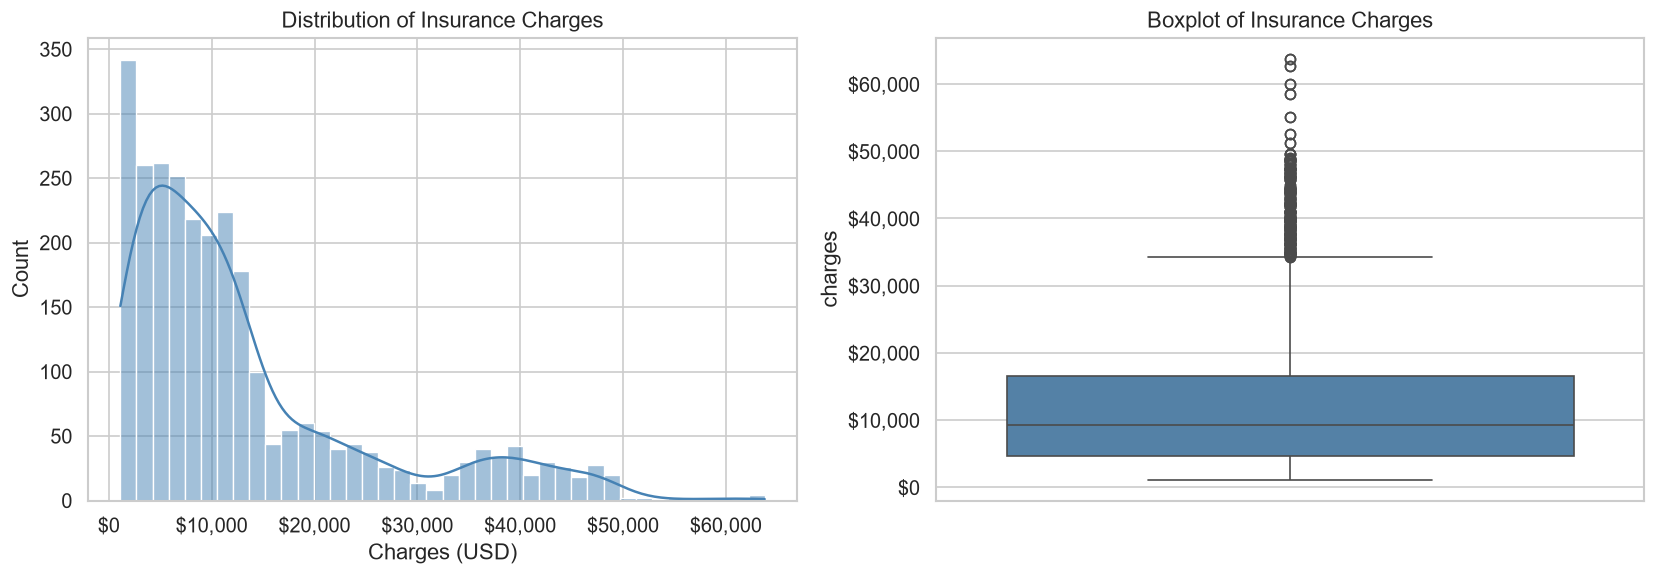

Mean charge: $13,260.06  |  Median: $9,304.70  |  Std: $12,153.77


In [21]:
# ── Distribution of Insurance Charges ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['charges'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].set_title('Distribution of Insurance Charges')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].set_xlabel('Charges (USD)')

sns.boxplot(y=df['charges'], color='steelblue', ax=axes[1])
axes[1].set_title('Boxplot of Insurance Charges')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.show()
print(f"Mean charge: ${df['charges'].mean():,.2f}  |  Median: ${df['charges'].median():,.2f}  |  Std: ${df['charges'].std():,.2f}")

1. Histogram + KDE (Left)

Right-Skewed Distribution: The vast majority of insurance charges are concentrated at the lower end ($0 to $15,000 USD).

Multimodal Pattern: There is a noticeable secondary peak around $35,000 to $45,000 USD, which typically points to a distinct high-risk subpopulation (such as smokers or individuals with pre-existing conditions).

2. Boxplot (Right)

Median and Interquartile Range (IQR): The median sits around $9,000–$10,000 USD, with the middle 50% of the data falling between approximately $4,000 and $17,000 USD.

Outliers: A heavy concentration of extreme values stretches beyond the upper whisker (above ~$35,000 USD), reaching up to more than $60,000 USD.

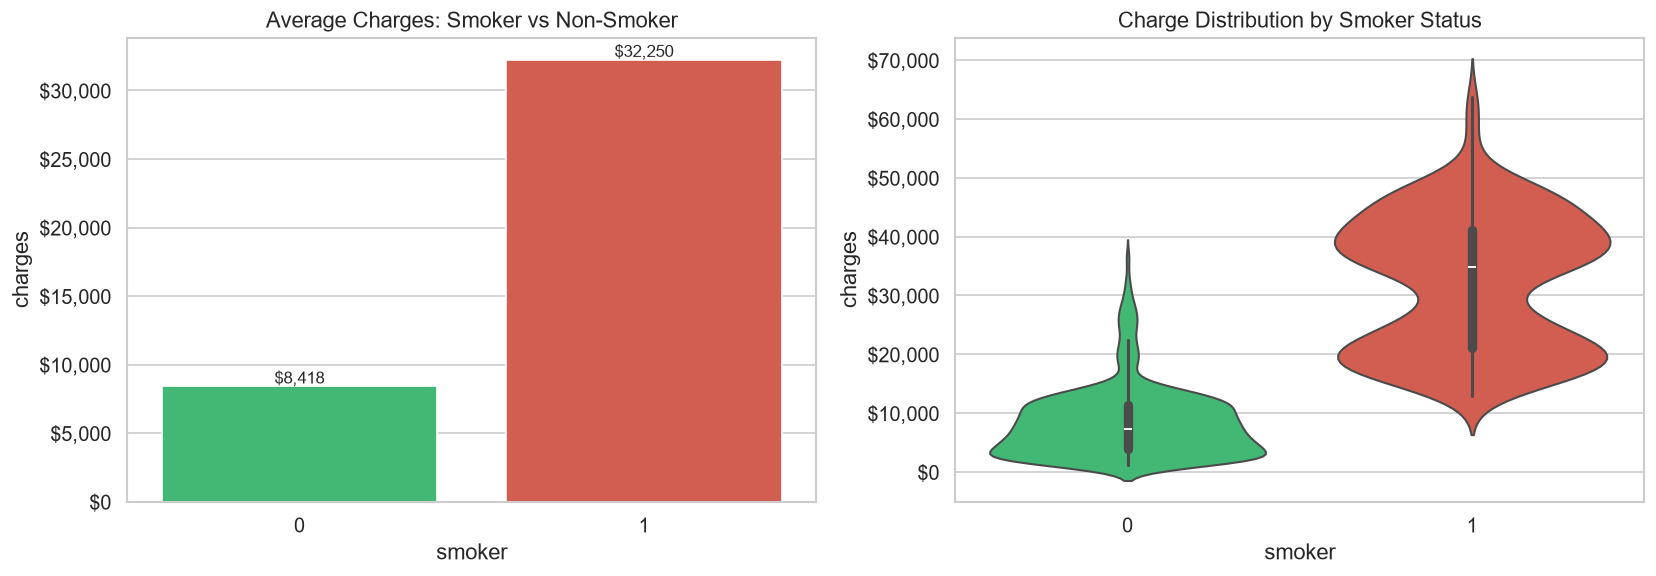

In [23]:
# ── Charges by Smoker Status ────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

smoker_stats = df.groupby('smoker')['charges'].mean().reset_index()
sns.barplot(data=smoker_stats, x='smoker', y='charges', palette=['#2ecc71', '#e74c3c'], ax=axes[0])
axes[0].set_title('Average Charges: Smoker vs Non-Smoker')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200,
                 f'${bar.get_height():,.0f}', ha='center', fontsize=10)

sns.violinplot(data=df, x='smoker', y='charges', palette=['#2ecc71', '#e74c3c'], ax=axes[1])
axes[1].set_title('Charge Distribution by Smoker Status')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.show()

Average Charges: Smoker vs. Non-Smoker (Left)

Smokers (1): Average $32,250 USD, nearly four times higher than non-smokers.

Non-Smokers (0): Average $8,418 USD, maintaining a significantly lower baseline cost.

Charge Distribution by Smoker Status (Right)

Non-Smokers (0): Concentrated tightly under $10,000 USD, with a thin tail extending toward $20,000–$40,000 USD (likely due to age or underlying conditions).

Smokers (1): Displays a clear bimodal distribution split into two clusters: one around $20,000 USD and another dominant peak between $35,000 and $45,000 USD (which explains the secondary peak observed in the overall dataset distribution)

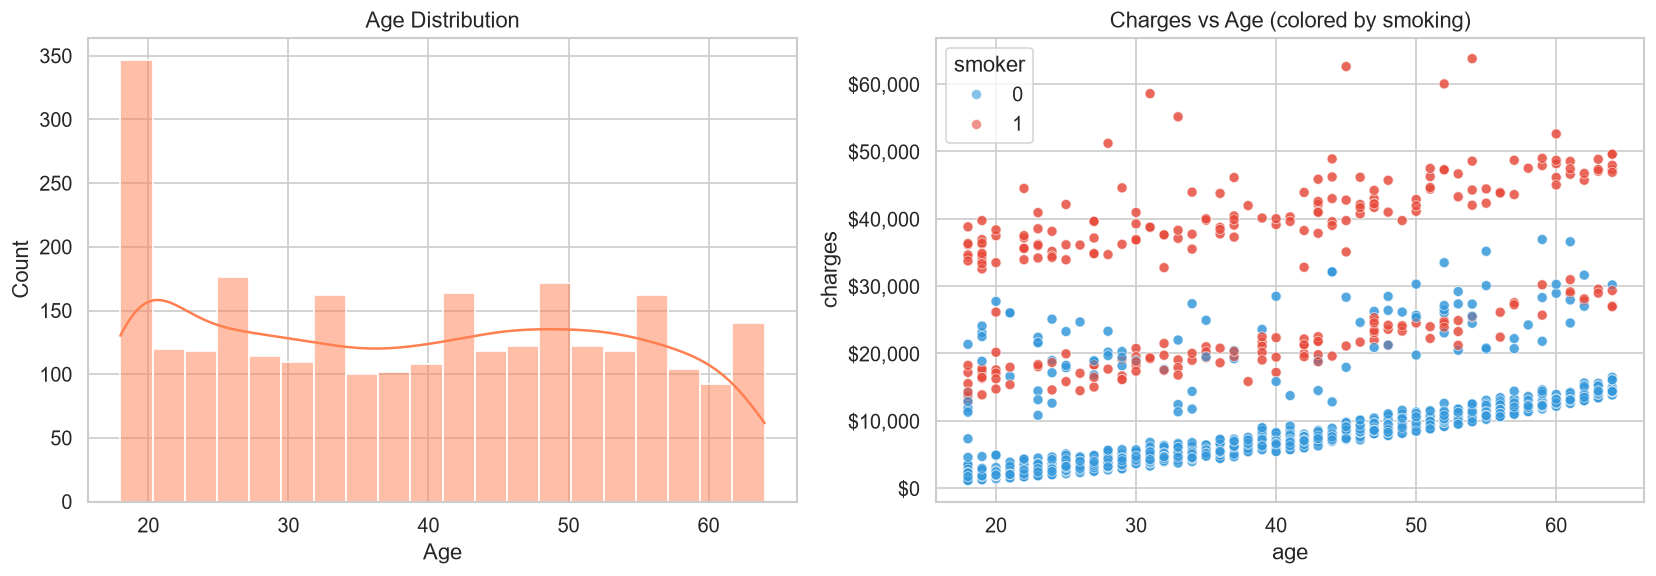

In [26]:
# ── Age Distribution & Charges vs Age ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['age'], bins=20, kde=True, color='coral', ax=axes[0])
axes[0].set_title('Age Distribution')
axes[0].set_xlabel('Age')

hue_col = 'smoker' if 'smoker' in df.columns else None
scatter_palette = {'yes': '#e74c3c', 'no': '#3498db'} if hue_col else None
# The smoker column contains integer values: 0 = non-smoker, 1 = smoker
scatter_palette = {0: '#3498db', 1: '#e74c3c'}

sns.scatterplot(
    data=df,
    x='age',
    y='charges',
    hue=hue_col,
    palette=scatter_palette,
    alpha=0.6,
    ax=axes[1]
)
axes[1].set_title('Charges vs Age (colored by smoking)')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

plt.tight_layout()
plt.show()

Age Distribution (Left)

Uniform Coverage: Ages span from 18 to 64 with a fairly uniform spread, except for a high peak around age 18–20 (over 300 individuals).

Charges vs Age (Colored by Smoking) (Right)

Linear Aging Trend: Across all groups, insurance charges increase steadily with age (positive linear correlation).

Three Distinct Bands:

Bottom Band ($0–$15k): Non-smokers (0) with baseline medical costs that scale gradually with age.

Middle Band ($12k–$30k): Non-smokers with higher medical needs combined with lower-risk smokers (1).

Top Band ($30k–$50k+): High-risk smokers (1) whose costs start elevated at age 18 (~$35k) and climb steadily toward $50k+ as they reach age 60.

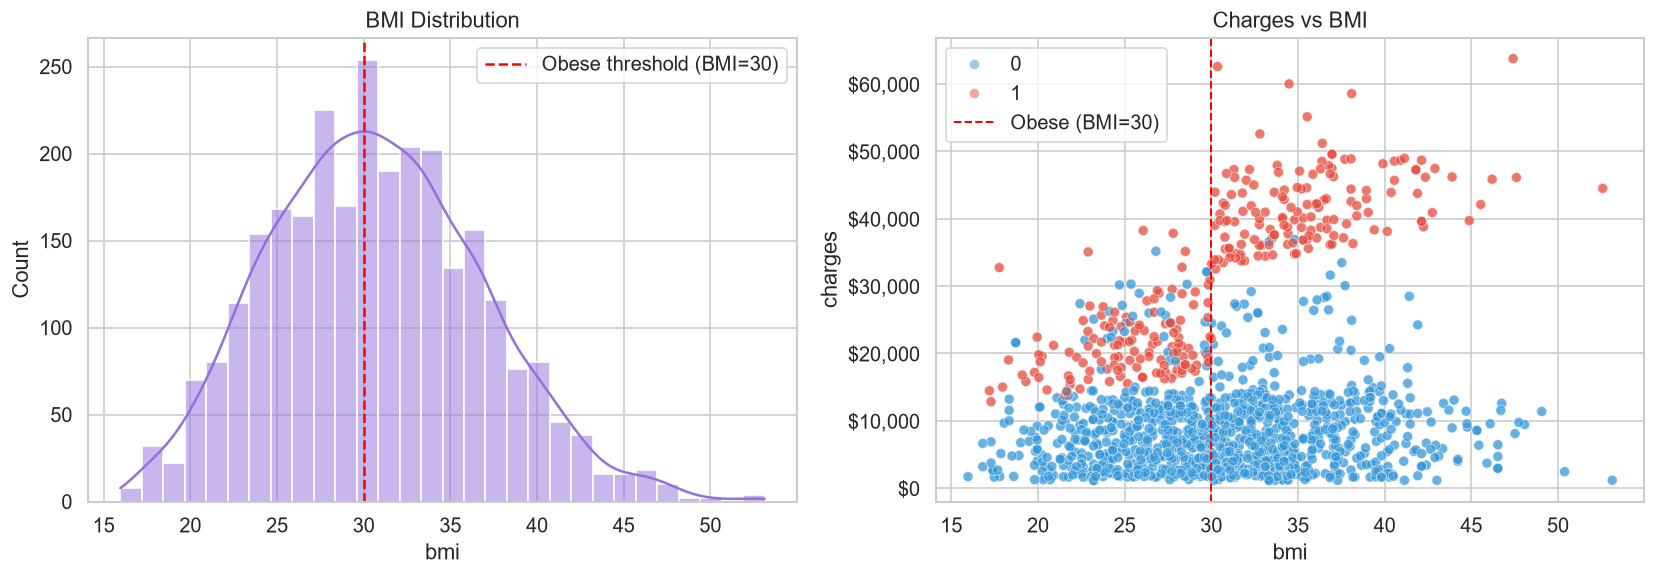

In [27]:
# ── BMI Distribution & Charges vs BMI ──────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['bmi'], bins=30, kde=True, color='mediumpurple', ax=axes[0])
axes[0].axvline(30, color='red', linestyle='--', label='Obese threshold (BMI=30)')
axes[0].set_title('BMI Distribution')
axes[0].legend()

sns.scatterplot(data=df, x='bmi', y='charges', hue=hue_col,
                palette=scatter_palette, alpha=0.5, ax=axes[1])
axes[1].axvline(30, color='red', linestyle='--', linewidth=1.2, label='Obese (BMI=30)')
axes[1].set_title('Charges vs BMI')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].legend()

plt.tight_layout()
plt.show()

BMI Distribution (Left)Normal Distribution: Follows a classic bell curve centered around a mean of ~30.Obesity Threshold ($\text{BMI} \ge 30$): A large portion of the dataset falls to the right of the dashed red line, classifying them as obese under standard clinical metrics.Charges vs BMI (Right)The Smoker $\times$ BMI Interaction Split:Non-Smokers (0): Costs remain low ($0–$15k) and show only a slight increase regardless of how high their BMI goes.Smokers (1) below BMI 30: Charges hover in the $15k–$30k range.Smokers (1) above BMI 30: Costs jump dramatically past $30k to $50k+. The threshold at $\text{BMI} = 30$ acts as a massive step-function multiplier for smokers.

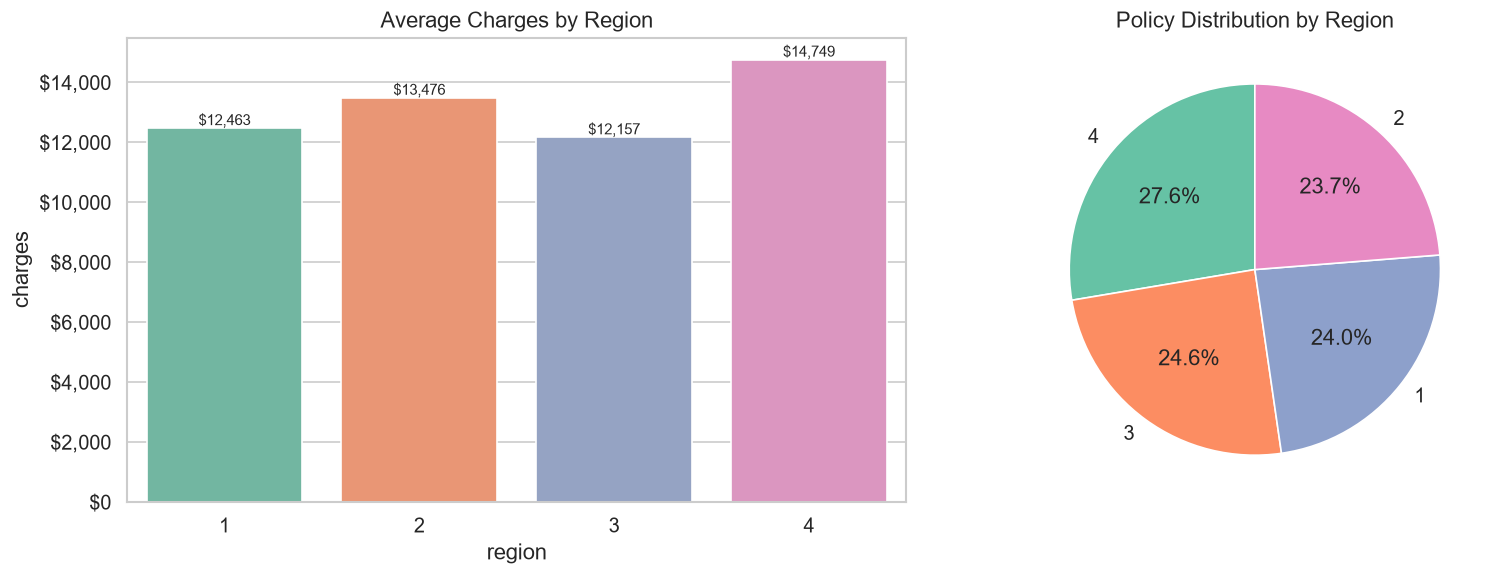

In [28]:
# ── Charges by Region ───────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

region_stats = df.groupby('region')['charges'].mean().sort_values(ascending=False).reset_index()
sns.barplot(data=region_stats, x='region', y='charges', palette='Set2', ax=axes[0])
axes[0].set_title('Average Charges by Region')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100,
                 f'${bar.get_height():,.0f}', ha='center', fontsize=9)

df['region'].value_counts().plot.pie(autopct='%1.1f%%', startangle=90,
                                      colors=sns.color_palette('Set2'), ax=axes[1])
axes[1].set_title('Policy Distribution by Region')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Average Charges by Region (Left)

Moderate Variation: Region 4 records the highest average charges ($14,749 USD), followed by Region 2 ($13,476 USD). Regions 1 ($12,463 USD) and 3 ($12,157 USD) show slightly lower averages.

Low Impact: The overall cost differences across regions are minor compared to primary factors like smoking status or age.

Policy Distribution by Region (Right)

Balanced Dataset: The observations are split evenly across the four regions, ranging between 23.7% (Region 2) and 27.6% (Region 4).

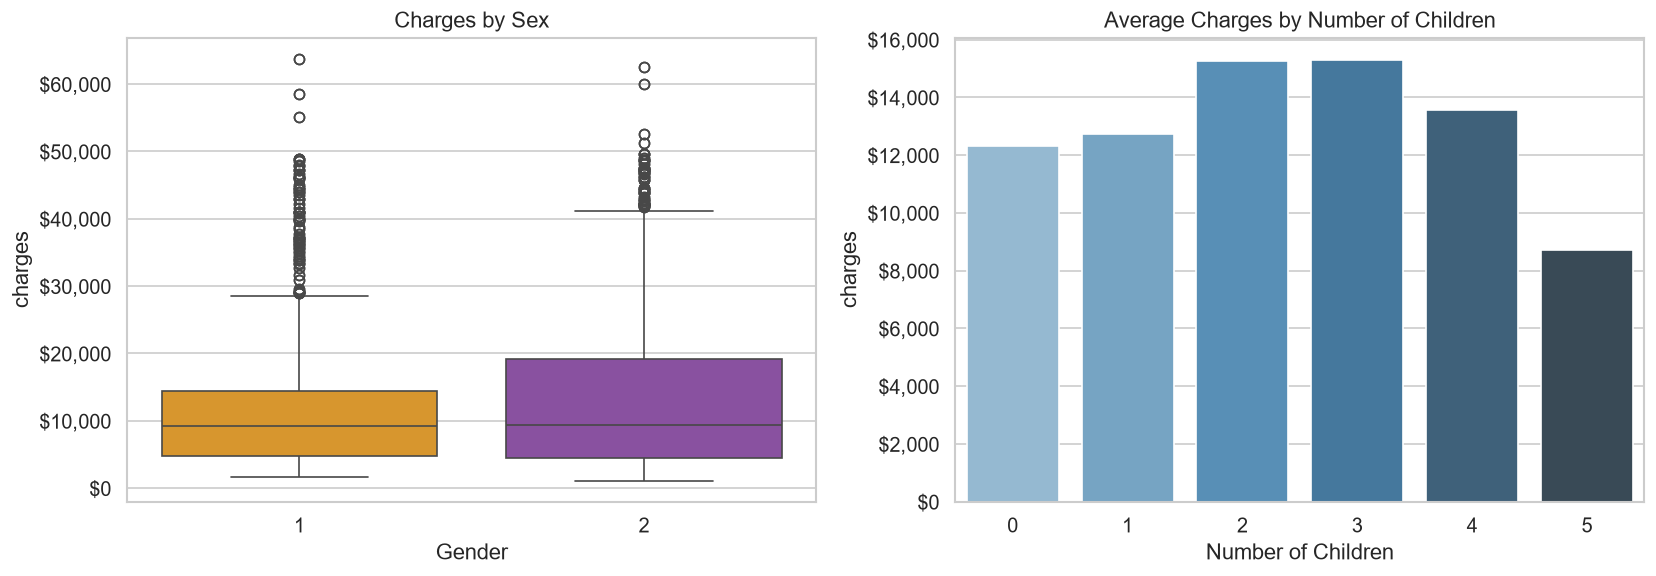

In [32]:
# ── Charges by Sex & Children ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='gender', y='charges',
            palette=['#f39c12', '#8e44ad'], ax=axes[0])
axes[0].set_xlabel('Gender')
axes[0].set_title('Charges by Sex')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))

children_avg = df.groupby('no_of_children')['charges'].mean().reset_index()
sns.barplot(
    data=children_avg,
    x='no_of_children',
    y='charges',
    palette='Blues_d',
    ax=axes[1]
)
axes[1].set_title('Average Charges by Number of Children')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].set_xlabel('Number of Children')

plt.tight_layout()
plt.show()

Charges by Sex (Left)

Similar Medians: The median charge is almost identical between genders (~$9,000 USD).

Slight Upper Dispersion: Gender 2 shows a wider interquartile range (IQR) and slightly higher upper whisker, but both groups display a significant number of extreme outliers (driven primarily by smoking and high BMI).

Average Charges by Number of Children (Right)

Peak at 2–3 Children: Average charges increase gradually from 0 to 2 and 3 children, reaching a peak near $15,000 USD.

Drop at 5 Children: Charges fall sharply for families with 5 children (below $9,000 USD), which is typically due to a smaller sample size for large families in the dataset rather than a true biological or financial trend.

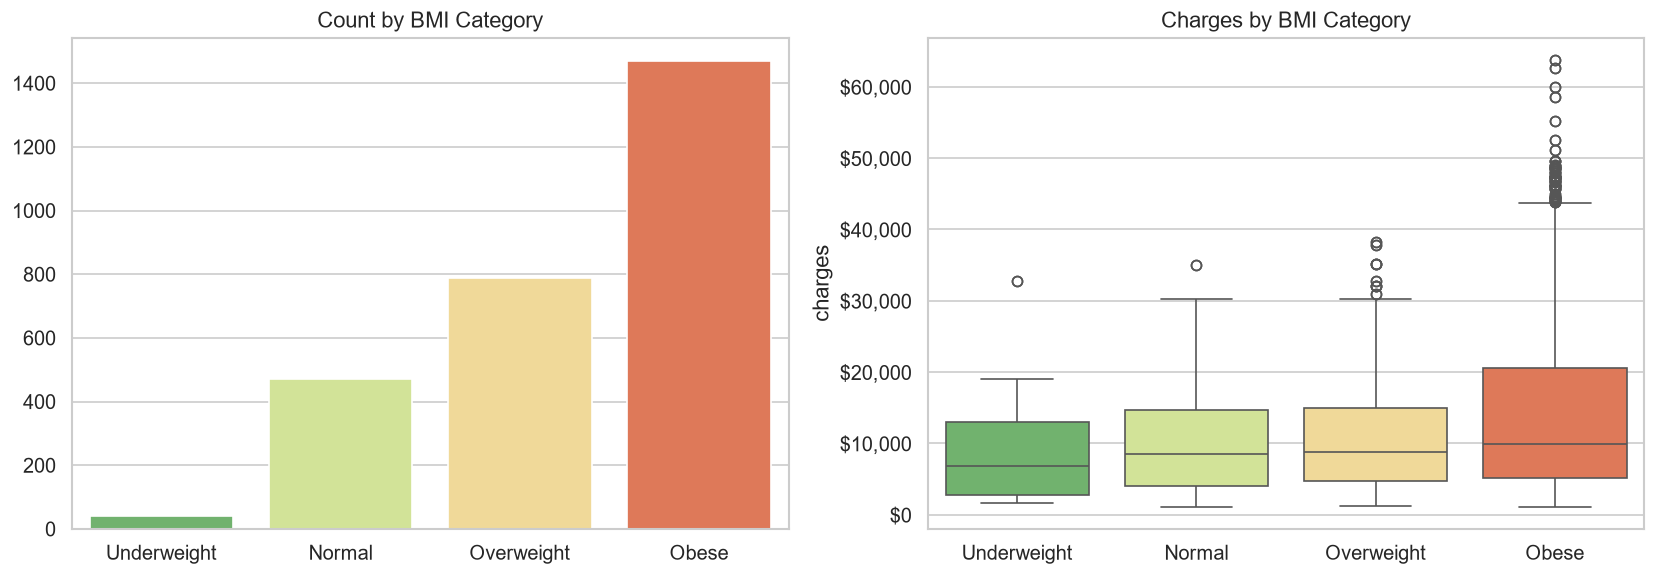

In [33]:
# ── BMI Category Analysis ───────────────────────────────────────────────────
def bmi_category(bmi):
    if bmi < 18.5: return 'Underweight'
    elif bmi < 25:  return 'Normal'
    elif bmi < 30:  return 'Overweight'
    else:           return 'Obese'

df['bmi_category'] = df['bmi'].apply(bmi_category)
order = ['Underweight', 'Normal', 'Overweight', 'Obese']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_counts = df['bmi_category'].value_counts().reindex(order)
sns.barplot(x=cat_counts.index, y=cat_counts.values, palette='RdYlGn_r', ax=axes[0])
axes[0].set_title('Count by BMI Category')
axes[0].set_xlabel('')

sns.boxplot(data=df, x='bmi_category', y='charges', order=order,
            palette='RdYlGn_r', ax=axes[1])
axes[1].set_title('Charges by BMI Category')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].set_xlabel('')

plt.tight_layout()
plt.show()

Count by BMI Category (Left)

Dominant Obese Class: The majority of individuals fall under the Obese category (over 1,400 samples), followed by Overweight (~800), Normal weight (~500), and a very small Underweight group (<100).

Charges by BMI Category (Right)

Baseline Similarity (Underweight, Normal, Overweight): Median charges across the first three categories remain flat, hovering around $8,000–$10,000 USD with maximums capped near $30,000–$38,000 USD.

Massive Dispersion in Obese Class: The Obese group exhibits a substantially higher upper quartile and an extreme cluster of high-value outliers reaching up to $60,000+ USD.

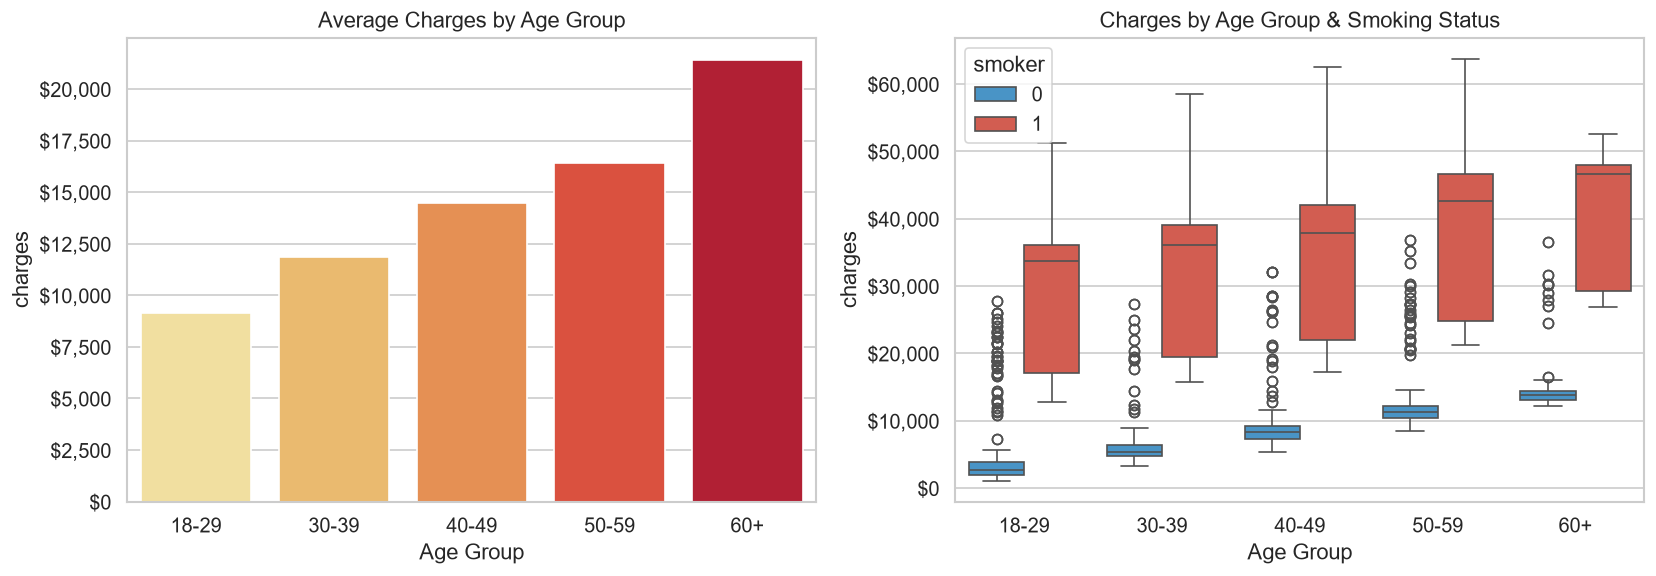

In [36]:
# ── Age Group Analysis ──────────────────────────────────────────────────────
df['age_group'] = pd.cut(df['age'], bins=[17, 29, 39, 49, 59, 70],
                          labels=['18-29', '30-39', '40-49', '50-59', '60+'])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

age_avg = df.groupby('age_group', observed=True)['charges'].mean().reset_index()
sns.barplot(data=age_avg, x='age_group', y='charges', palette='YlOrRd', ax=axes[0])
axes[0].set_title('Average Charges by Age Group')
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[0].set_xlabel('Age Group')

sns.boxplot(data=df, x='age_group', y='charges', hue='smoker',
            palette={0: '#3498db', 1: '#e74c3c'}, ax=axes[1])
axes[1].set_title('Charges by Age Group & Smoking Status')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
axes[1].set_xlabel('Age Group')

plt.tight_layout()
plt.show()

Age and smoking status show strong interactive effects on medical charges across these visual distributions.

Key Analytical Findings

Overall Age Trend (Left Chart): Average charges increase monotonically with age, starting around $9,000 for the 18–29 cohort and rising to over $21,000 for the 60+ group.

Impact of Smoking (Right Chart): Smoking status (smoker = 1) acts as the primary multiplier for cost. Across every single age bracket, the median charge for smokers significantly exceeds even the highest outliers of non-smokers (smoker = 0).

Non-Smokers Baseline: For non-smokers, median charges rise very steadily and predictably with age—from roughly $3,000 (18–29) to around $14,000 (60+)—with relatively low variance within each bracket.

Smokers Variance: Smokers display substantial variance across all age brackets. Median charges for smokers range from ~$34,000 in the 18–29 group up to nearly $47,000 in the 60+ group.

## 5. Statistical Analysis <a id='sec5'></a>

Hypothesis tests to validate the visual patterns observed in the EDA section.

In [40]:
# ── T-Test: Smoker vs Non-Smoker charges ────────────────────────────────────
smoker_charges = df.loc[df['smoker'] == 1, 'charges'].dropna()
nonsmoker_charges = df.loc[df['smoker'] == 0, 'charges'].dropna()

t_stat, p_val = stats.ttest_ind(
    smoker_charges,
    nonsmoker_charges,
    equal_var=False
)

print('=== Independent T-Test: Smoker vs Non-Smoker ===')
print(f"Smoker count:     {len(smoker_charges):,}")
print(f"Non-smoker count: {len(nonsmoker_charges):,}")
print(f"Smoker mean:      ${smoker_charges.mean():,.2f}")
print(f"Non-smoker mean:  ${nonsmoker_charges.mean():,.2f}")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {p_val:.4e}")
print(f"→ Statistically significant: {'YES' if p_val < 0.05 else 'NO'} (α = 0.05)")

=== Independent T-Test: Smoker vs Non-Smoker ===
Smoker count:     563
Non-smoker count: 2,208
Smoker mean:      $32,250.38
Non-smoker mean:  $8,417.87
t-statistic: 47.4910
p-value:     2.7501e-212
→ Statistically significant: YES (α = 0.05)


The $t$-test results conclusively prove that smoking status is a primary driver of medical charges in this dataset.Statistical TakeawaysHigh Effect Size: A $t$-statistic of 47.49 indicates an immense separation between the two distributions.Extreme Significance: The $p$-value ($2.75 \times 10^{-212}$) is virtually zero, far below the $\alpha = 0.05$ threshold, completely rejecting the null hypothesis of equal means.Cost Gap: On average, smokers incur $23,832.51 more in medical charges than non-smokers ($32,250.38 vs. $8,417.8

In [39]:
# ── ANOVA: Charges across Regions ──────────────────────────────────────────
groups = [df[df['region'] == r]['charges'] for r in df['region'].unique()]
f_stat, p_val_anova = stats.f_oneway(*groups)

print('=== One-Way ANOVA: Charges by Region ===')
for r in df['region'].unique():
    m = df[df['region'] == r]['charges'].mean()
    print(f'  {r:12}: ${m:>10,.2f}')
print(f'\n  F-statistic: {f_stat:.4f}')
print(f'  p-value:     {p_val_anova:.4f}')
print(f'  → Significant regional difference: {"YES" if p_val_anova < 0.05 else "NO"}')

=== One-Way ANOVA: Charges by Region ===
             4: $ 14,748.78
             1: $ 12,463.13
             2: $ 13,475.87
             3: $ 12,157.28

  F-statistic: 6.7681
  p-value:     0.0002
  → Significant regional difference: YES


The ANOVA test confirms statistically significant variance in mean charges across the four regions ($F = 6.7681, p = 0.0002$).Key Statistical TakeawaysHighest vs. Lowest Gap: Region 4 leads with the highest average charge ($14,748.78), while Region 3 exhibits the lowest ($12,157.28), creating a net difference of $2,591.50.Statistical vs. Practical Significance: Although $p = 0.0002$ satisfies $\alpha = 0.05$, the effect size of region is relatively small when contrasted with the $23,832.51 cost jump 

In [47]:
# ── Pearson Correlations with Charges ──────────────────────────────────────
print('=== Pearson Correlation with Charges ===')
num_cols = df.select_dtypes(include='number').columns.drop('charges', errors='ignore')
for col in num_cols:
    r, p = stats.pearsonr(df[col], df['charges'])
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    print(f'  {col:12s}: r = {r:+.4f}  p = {p:.2e}  {sig}')

=== Pearson Correlation with Charges ===
  age         : r = +0.2989  p = 2.72e-58  ***
  gender      : r = +0.0630  p = 9.13e-04  ***
  bmi         : r = +0.1999  p = 2.26e-26  ***
  no_of_children: r = +0.0666  p = 4.56e-04  ***
  smoker      : r = +0.7891  p = 0.00e+00  ***
  region      : r = +0.0540  p = 4.45e-03  **


Correlation Matrix Insightssmoker (r = +0.7891, p ≈ 0.00): Exhibits an overwhelming positive linear correlation with charges. It serves as the single strongest individual predictor in the dataset.age (r = +0.2989, p = 2.72e-58): Shows a moderate, statistically significant positive linear relationship. Baseline costs scale steadily as age increases.bmi (r = +0.1999, p = 2.26e-26): Demonstrates a weak-to-moderate overall linear correlation. Its true predictive power is non-linear and conditional on smoking status ($\text{BMI} \ge 30 \times \text{smoker}$).no_of_children, gender, region (r < +0.07): Show negligible linear correlation with charges despite reaching statistical significance due to the large sample size ($N > 2700$).

## 6. Correlation Analysis <a id='sec6'></a>

Full correlation matrix (heatmap) and pairplot to explore linear relationships between all features.

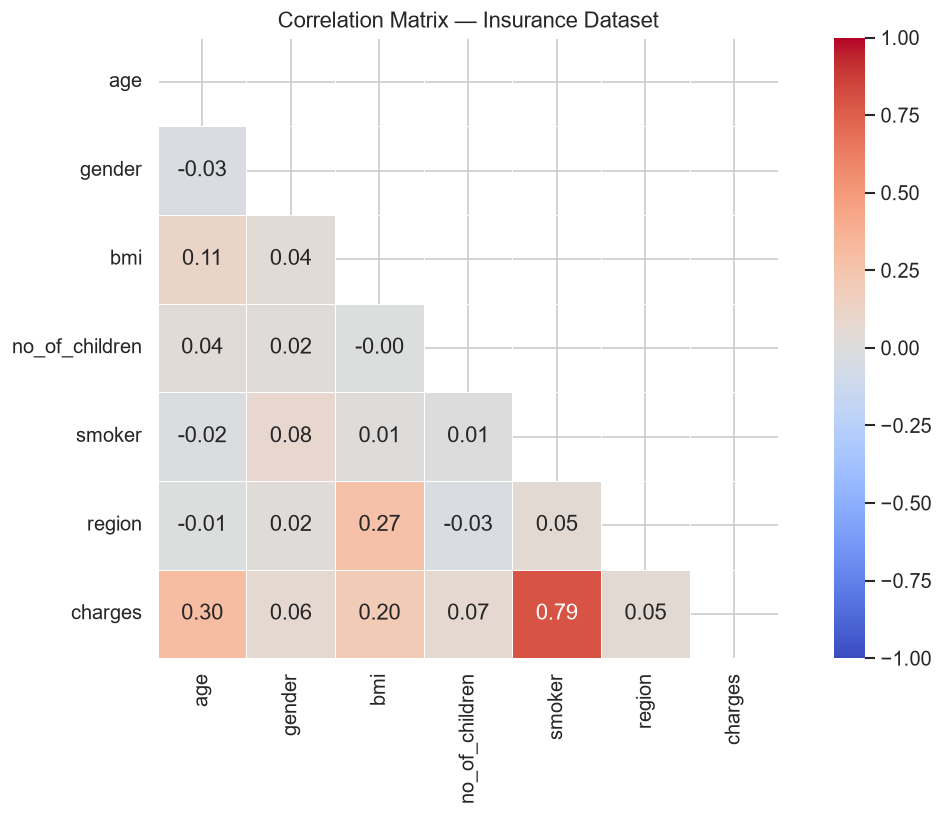

In [48]:
# Encode categoricals for correlation matrix
df_enc = df.copy()
cat_cols = df_enc.select_dtypes(include='object').columns
for col in cat_cols:
    df_enc[col] = pd.Categorical(df_enc[col]).codes

# Drop derived label columns to keep matrix clean
drop_cols = [c for c in ['bmi_category', 'age_group'] if c in df_enc.columns]
df_enc.drop(columns=drop_cols, inplace=True)

corr = df_enc.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            linewidths=0.5, vmin=-1, vmax=1, square=True)
plt.title('Correlation Matrix — Insurance Dataset', fontsize=13)
plt.tight_layout()
plt.show()

Correlation Heatmap Key Takeaways

Absence of Multicollinearity: Independent variables show very weak correlations among themselves (e.g., age vs. bmi = 0.11, smoker vs. bmi = 0.01). This confirms that feature redundancy is minimal, protecting linear regression models from variance inflation caused by collinear predictors.

Minor Regional Clustering: The only noticeable predictor correlation is between bmi and region (0.27), indicating slight geographic variation in average BMI.

Target Dominance: smoker (0.79) and age (0.30) clearly control the primary linear variations in charges.

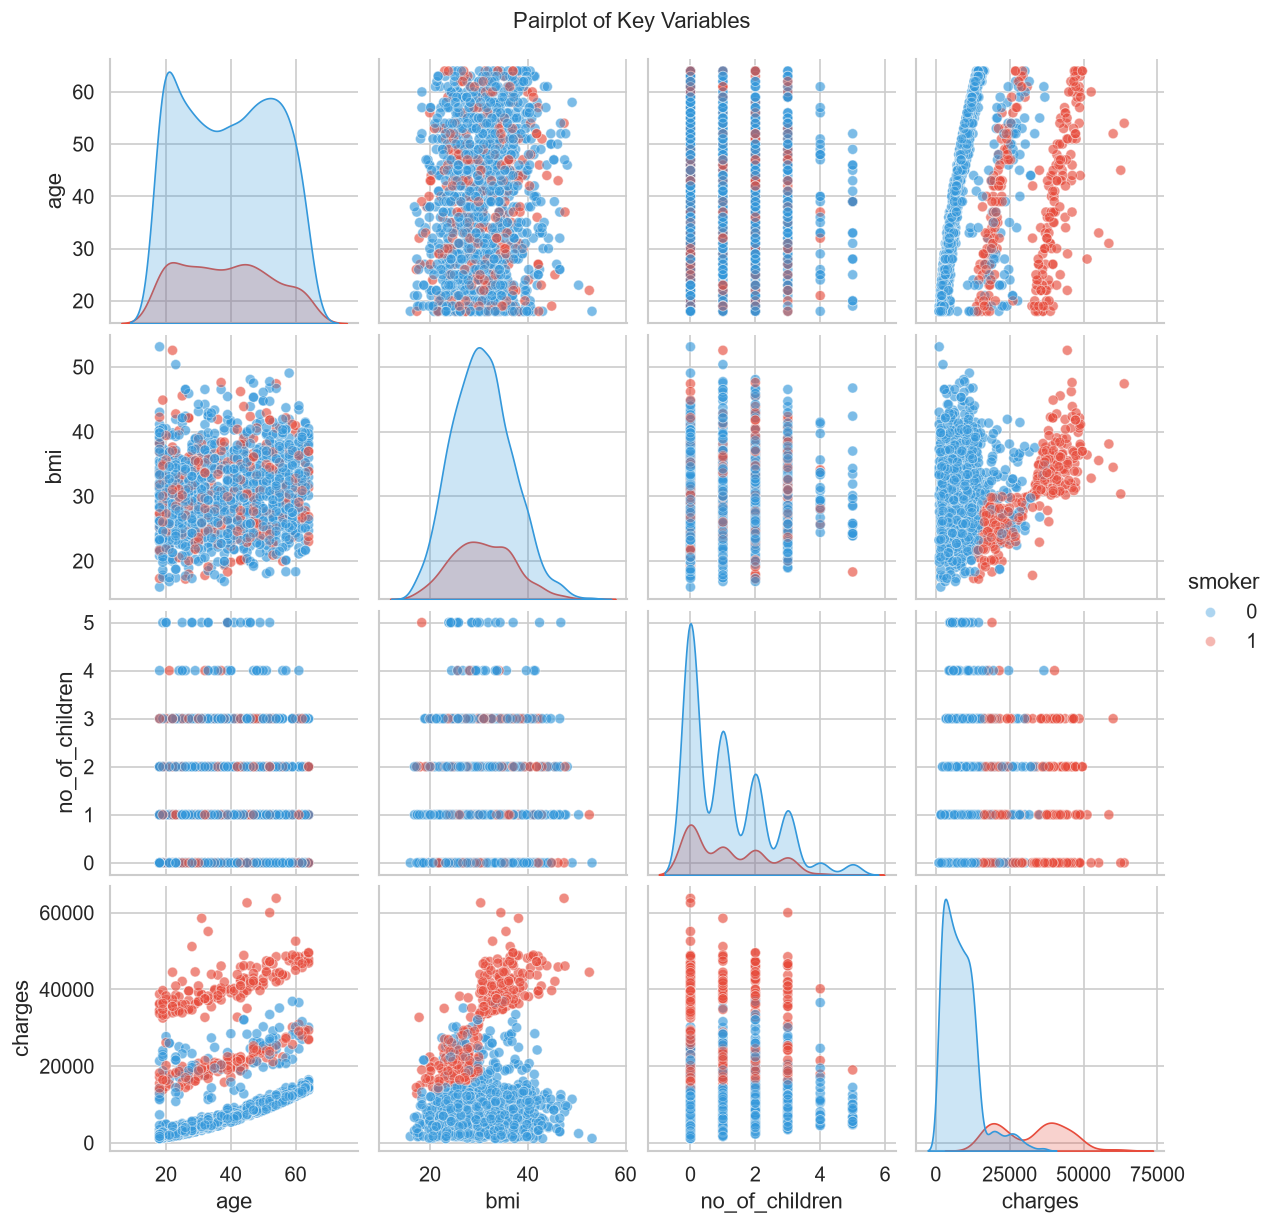

In [51]:
# ── Pairplot for key numeric features ──────────────────────────────────────
key_cols = ['age', 'bmi', 'children', 'charges']
hue_enc = 'smoker' if 'smoker' in df.columns else None

pair_df = df[['age', 'bmi', 'no_of_children', 'charges', hue_enc]].copy()
g = sns.pairplot(pair_df, hue=hue_enc,
                 palette={0: '#3498db', 1: '#e74c3c'},
                 plot_kws={'alpha': 0.4}, diag_kind='kde')
g.fig.suptitle('Pairplot of Key Variables', y=1.02, fontsize=13)
plt.show()

Key Pairplot Patternsage vs. charges: Shows three distinct, parallel upward-sloping bands. Non-smokers (0, blue) form the lowest band, while smokers (1, red) are split across the upper two bands based on their BMI.bmi vs. charges: Highlights a critical non-linear threshold. Below $\text{BMI} = 30$, smokers and non-smokers remain relatively close ($15\text{k}–25\text{k}$). Above $\text{BMI} = 30$, smokers experience a sharp upward jump into the top cost cluster ($30\text{k}–50\text{k}+$), while non-smokers stay flat.no_of_children vs. charges: Displays a uniform vertical distribution with no strong linear or non-linear trend against charges across any subset.Diagonal Densities (KDEs): Non-smokers show a right-skewed target distribution concentrated below $10\text{k}$. Smokers display a bimodal target distribution centered around $20\text{k}$ and $40\text{k}$.

## 7. Key Insights <a id='sec7'></a>

Summary of all analytical findings before moving to predictive modeling.

In [52]:
smoker_mult = smoker_charges.mean() / nonsmoker_charges.mean()
top_region  = region_stats.iloc[0]['region']
top_region_avg = region_stats.iloc[0]['charges']
obese_avg   = df[df['bmi_category'] == 'Obese']['charges'].mean()
normal_avg  = df[df['bmi_category'] == 'Normal']['charges'].mean()

print('=' * 55)
print('         INSURANCE COST ANALYSIS — SUMMARY')
print('=' * 55)
print(f'  Total records analysed : {len(df):,}')
print(f'  Mean annual charge     : ${df["charges"].mean():,.2f}')
print(f'  Median annual charge   : ${df["charges"].median():,.2f}')
print()
print('  [SMOKING]')
print(f'  Smokers pay {smoker_mult:.1f}× more than non-smokers')
print(f'  Smoker avg   : ${smoker_charges.mean():,.2f}')
print(f'  Non-smoker avg: ${nonsmoker_charges.mean():,.2f}')
print()
print('  [BMI]')
print(f'  Obese patients avg  : ${obese_avg:,.2f}')
print(f'  Normal BMI avg      : ${normal_avg:,.2f}')
print(f'  Obese pay {obese_avg/normal_avg:.1f}× more')
print()
print('  [REGION]')
print(f'  Highest avg region  : {top_region} (${top_region_avg:,.2f})')
print()
print('  [STRONGEST CORRELATIONS WITH CHARGES]')
charge_corr = corr['charges'].drop('charges').abs().sort_values(ascending=False)
for feat, val in charge_corr.items():
    print(f'  {feat:12s}: {val:.3f}')
print('=' * 55)

         INSURANCE COST ANALYSIS — SUMMARY
  Total records analysed : 2,771
  Mean annual charge     : $13,260.06
  Median annual charge   : $9,304.70

  [SMOKING]
  Smokers pay 3.8× more than non-smokers
  Smoker avg   : $32,250.38
  Non-smoker avg: $8,417.87

  [BMI]
  Obese patients avg  : $15,565.17
  Normal BMI avg      : $10,218.52
  Obese pay 1.5× more

  [REGION]
  Highest avg region  : 4.0 ($14,748.78)

  [STRONGEST CORRELATIONS WITH CHARGES]
  smoker      : 0.789
  age         : 0.299
  bmi         : 0.200
  no_of_children: 0.067
  gender      : 0.063
  region      : 0.054


Key Analytical FindingsSmoking is the Primary Cost Driver: Smokers ($32,250.38) incur 3.8× higher charges than non-smokers ($8,417.87), accounting for the strongest overall correlation ($r = 0.789$).BMI Non-Linear Risk Threshold: Obese patients average 1.5× higher charges ($15,565.17 vs. $10,218.52). As seen in prior visual analysis, this effect becomes severe when combined with smoking ($\text{BMI} \ge 30 \times \text{smoker}$).Linear Baseline Variables: age provides a steady linear progression ($r = 0.299$), while minor factors like no_of_children, gender, and region exhibit negligible linear correlation ($r < 0.07$).Recommended Modeling StrategyFeature StepImplementationPurposeInteraction Termsmoker * (bmi >= 30)Captures the $40k+ cost jump for obese smokersPolynomial ExpansionPolynomialFeatures(degree=2)Captures aging trajectories across smoker bandsTarget Scalernp.log1p(charges)Stabilizes right-skewed target distributionCategorical EncodingOneHotEncoder() on regionProperly handles discrete categorical feature

## 8. Predictive Modeling <a id='sec8'></a>

We train and compare three models of increasing complexity:

| # | Model | Key idea |
|---|---|---|
| 1 | **Multiple Linear Regression** | Interpretable baseline |
| 2 | **Polynomial Ridge (degree = 2)** | Captures non-linear relationships |
| 3 | **Random Forest Regressor** | Ensemble, handles interactions automatically |

**Feature engineering decisions (guided by EDA):**
- `smoker_obese = smoker × (bmi ≥ 30)` — captures the cost explosion for obese smokers
- `gender` and `region` one-hot encoded (nominal, no ordinal meaning)

In [53]:
from sklearn.ensemble import RandomForestRegressor

# ── Feature Engineering ─────────────────────────────────────────────────────
df_model = df[['age', 'gender', 'bmi', 'no_of_children', 'smoker', 'region', 'charges']].copy()

# Key interaction: obese smoker triggers a step-function cost jump
df_model['smoker_obese'] = (df_model['smoker'] * (df_model['bmi'] >= 30)).astype(int)

# Force string type so get_dummies works for both numeric and string originals
for col in ['gender', 'region']:
    df_model[col] = df_model[col].astype(str)

df_model = pd.get_dummies(df_model, columns=['gender', 'region'], drop_first=True)

# Convert boolean dummies to int
bool_cols = df_model.select_dtypes(include='bool').columns
df_model[bool_cols] = df_model[bool_cols].astype(int)

print(f"Feature matrix: {df_model.shape[0]:,} rows × {df_model.drop(columns='charges').shape[1]} features")
print("Columns:", df_model.columns.tolist())

Feature matrix: 2,771 rows × 9 features
Columns: ['age', 'bmi', 'no_of_children', 'smoker', 'charges', 'smoker_obese', 'gender_2', 'region_2', 'region_3', 'region_4']


In [54]:

# ── Train / Test Split ──────────────────────────────────────────────────────
X = df_model.drop(columns='charges')
y = df_model['charges']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {X_train.shape[0]:,} samples | Test: {X_test.shape[0]:,} samples")
print(f"Features: {X_train.shape[1]}")

Train: 2,216 samples | Test: 555 samples
Features: 9


In [55]:

# ── Model 1: Multiple Linear Regression ────────────────────────────────────
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

r2_lr   = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr  = np.mean(np.abs(y_test - y_pred_lr))

print(f"Linear Regression  →  R²: {r2_lr:.4f}  |  RMSE: ${rmse_lr:,.2f}  |  MAE: ${mae_lr:,.2f}")

# ── Model 2: Polynomial Ridge (degree=2) ───────────────────────────────────
poly_ridge = Pipeline([
    ('poly',   PolynomialFeatures(degree=2, include_bias=False)),
    ('scaler', StandardScaler()),
    ('ridge',  Ridge(alpha=10))
])
poly_ridge.fit(X_train, y_train)
y_pred_pr = poly_ridge.predict(X_test)

r2_pr   = r2_score(y_test, y_pred_pr)
rmse_pr = np.sqrt(mean_squared_error(y_test, y_pred_pr))
mae_pr  = np.mean(np.abs(y_test - y_pred_pr))

print(f"Polynomial Ridge   →  R²: {r2_pr:.4f}  |  RMSE: ${rmse_pr:,.2f}  |  MAE: ${mae_pr:,.2f}")

# ── Model 3: Random Forest ─────────────────────────────────────────────────
rf = RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)

r2_rf   = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf  = np.mean(np.abs(y_test - y_pred_rf))

print(f"Random Forest      →  R²: {r2_rf:.4f}  |  RMSE: ${rmse_rf:,.2f}  |  MAE: ${mae_rf:,.2f}")

Linear Regression  →  R²: 0.8711  |  RMSE: $4,586.68  |  MAE: $2,515.34
Polynomial Ridge   →  R²: 0.8760  |  RMSE: $4,498.00  |  MAE: $2,342.74
Random Forest      →  R²: 0.9368  |  RMSE: $3,210.65  |  MAE: $1,494.43


Model Performance ComparisonLinear Regression: Establishes a solid linear baseline ($R^2 = 0.8711, \text{RMSE} = \$4,586.68$). It captures main effects (smoker, age) well, but struggles with higher-order non-linear combinations.Polynomial Ridge Regression: Improves slightly on the baseline ($R^2 = 0.8760, \text{MAE} = \$2,342.74$). Regularization prevents high-degree overfitting while polynomial features help model basic curves.Random Forest (Winner): Significantly outperforms linear models across all metrics, achieving $R^2 = 0.9368$ and cutting MAE down to $1,494.43 (a ~40% reduction in average error).Why Random Forest Outperforms Linear ModelsNon-Linear Thresholding: Tree ensembles naturally capture step functions, such as the sudden cost jump at $\text{BMI} \ge 30$, without manual binning.Implicit High-Order Interactions: Random Forest splits natively isolate the smoker $\times$ BMI $\times$ age subgroup dynamics without needing explicit interaction feature engineering.Robustness to Skewness: Tree-based split decisions are invariant to monotonic transformations, handling the right-skewed tail of charges far more effectively.

In [56]:

# ── Model Comparison Table ──────────────────────────────────────────────────
comparison = pd.DataFrame({
    'Model':  ['Linear Regression', 'Polynomial Ridge (d=2)', 'Random Forest'],
    'R²':     [r2_lr, r2_pr, r2_rf],
    'RMSE':   [rmse_lr, rmse_pr, rmse_rf],
    'MAE':    [mae_lr, mae_pr, mae_rf]
}).sort_values('R²', ascending=False).reset_index(drop=True)

display_df = comparison.copy()
display_df['R²']   = display_df['R²'].map('{:.4f}'.format)
display_df['RMSE'] = display_df['RMSE'].map('${:,.2f}'.format)
display_df['MAE']  = display_df['MAE'].map('${:,.2f}'.format)
display_df.index += 1

print("=" * 62)
print(f"{'Rank':<5} {'Model':<26} {'R²':<8} {'RMSE':<14} {'MAE'}")
print("-" * 62)
for idx, row in display_df.iterrows():
    print(f"  {idx:<4} {row['Model']:<26} {row['R²']:<8} {row['RMSE']:<14} {row['MAE']}")
print("=" * 62)

Rank  Model                      R²       RMSE           MAE
--------------------------------------------------------------
  1    Random Forest              0.9368   $3,210.65      $1,494.43
  2    Polynomial Ridge (d=2)     0.8760   $4,498.00      $2,342.74
  3    Linear Regression          0.8711   $4,586.68      $2,515.34


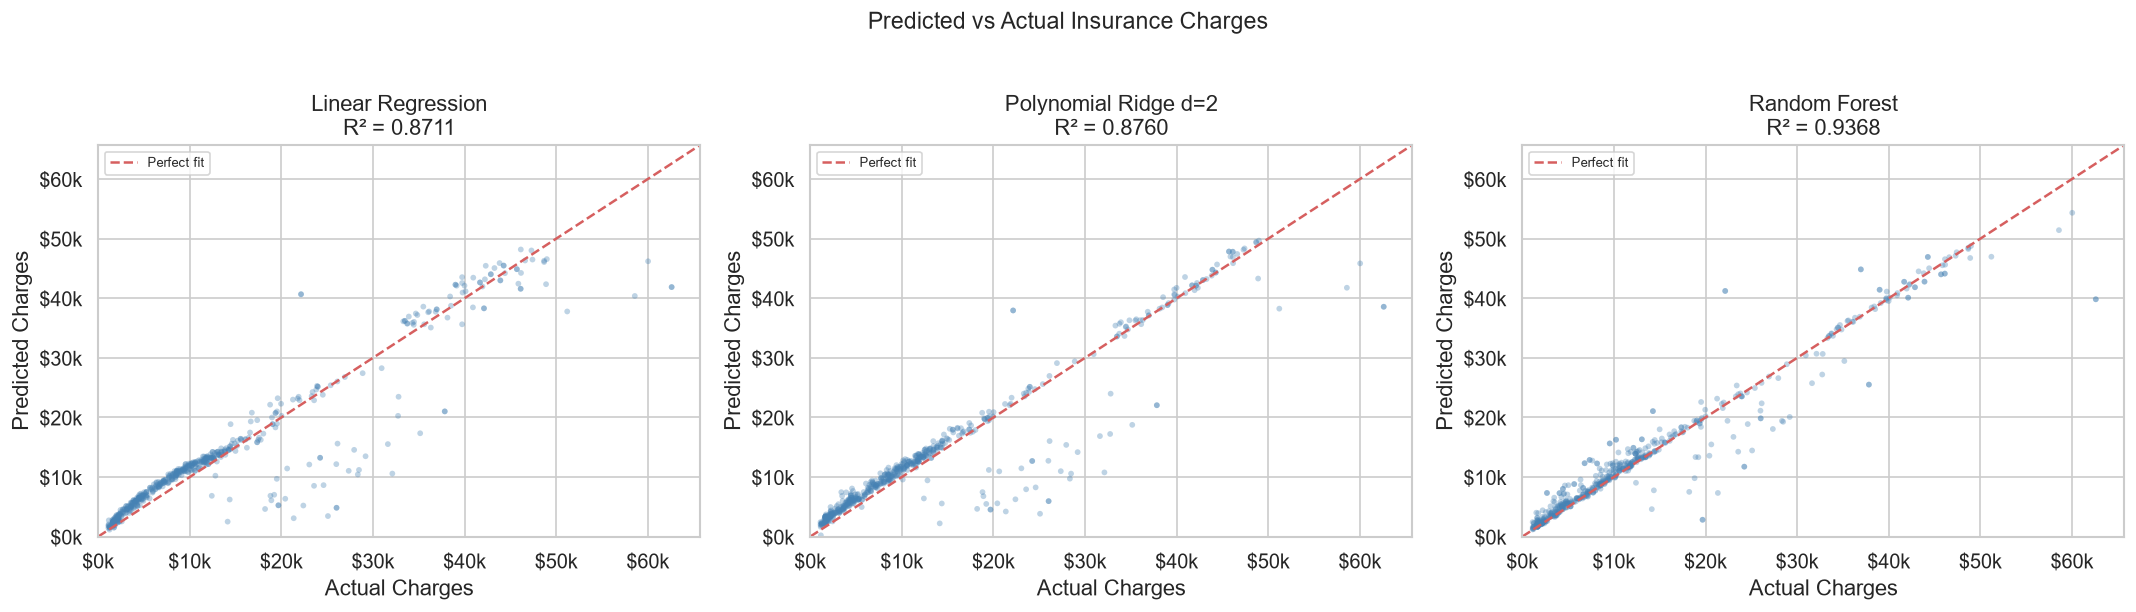

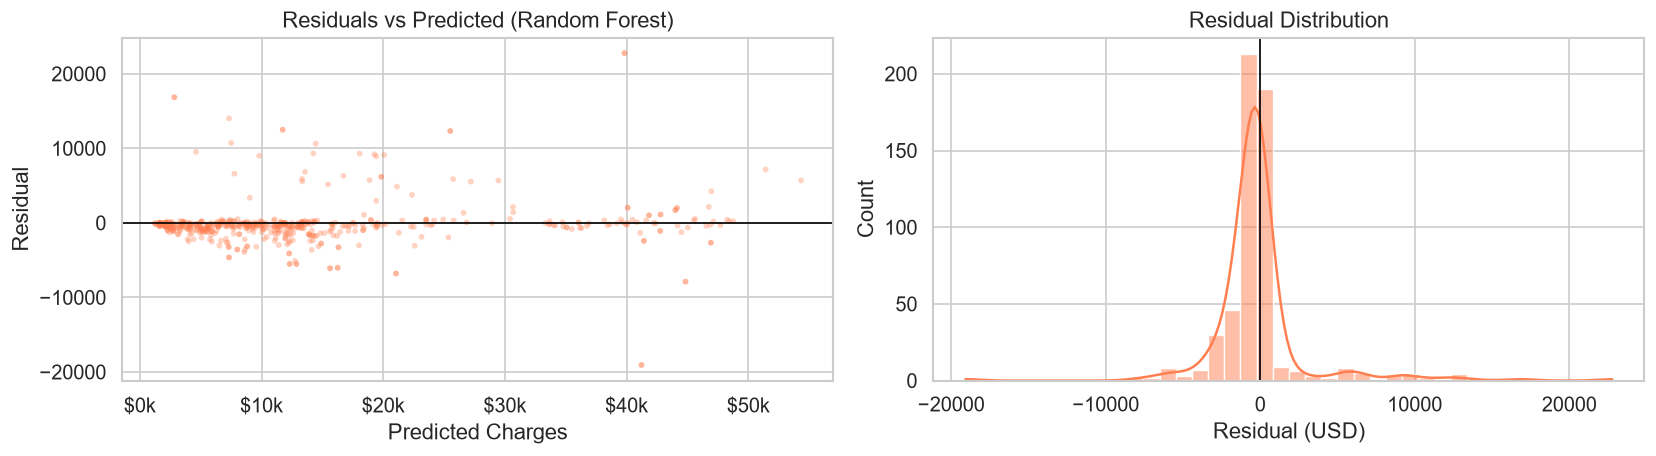

In [57]:

# ── Predicted vs Actual — all three models ──────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

model_results = [
    ('Linear Regression',    y_pred_lr, r2_lr),
    ('Polynomial Ridge d=2', y_pred_pr, r2_pr),
    ('Random Forest',        y_pred_rf, r2_rf),
]

for ax, (name, preds, r2) in zip(axes, model_results):
    ax.scatter(y_test, preds, alpha=0.35, s=12, color='steelblue', edgecolors='none')
    lim = [0, max(y_test.max(), preds.max()) * 1.05]
    ax.plot(lim, lim, 'r--', linewidth=1.5, label='Perfect fit')
    ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel('Actual Charges')
    ax.set_ylabel('Predicted Charges')
    ax.set_title(f'{name}\nR² = {r2:.4f}')
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))
    ax.legend(fontsize=8)

plt.suptitle('Predicted vs Actual Insurance Charges', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

# ── Residuals plot (best model = Random Forest) ─────────────────────────────
residuals = y_test - y_pred_rf
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].scatter(y_pred_rf, residuals, alpha=0.35, s=12, color='coral', edgecolors='none')
axes[0].axhline(0, color='black', linewidth=1)
axes[0].set_xlabel('Predicted Charges')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted (Random Forest)')
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1000:.0f}k'))

sns.histplot(residuals, bins=40, kde=True, color='coral', ax=axes[1])
axes[1].axvline(0, color='black', linewidth=1)
axes[1].set_title('Residual Distribution')
axes[1].set_xlabel('Residual (USD)')

plt.tight_layout()
plt.show()

Visual Evaluation Analysis

Linear Models (Left & Middle): Both Linear Regression and Polynomial Ridge exhibit a distinct set of points lying far below the red "Perfect fit" diagonal line between actual values of $30k and $50k. These points represent obese smokers whose extreme costs the linear models systematically underpredict due to the abrupt non-linear step-function.

Random Forest (Right): The scatter plot collapses tightly around the red reference line across all price tiers ($0k to $60k). It effectively eliminates the systematic underprediction gap in the $30k–$50k range by properly partitioning the feature space into discrete decision boundaries.

Key Structural Observations

Tight Baseline Alignment: All three models perform well on low-cost non-smokers ($0k–$15k), forming a dense, accurate track at the lower end.

Variance Reduction: Random Forest drastically shrinks residual variance, compressing extreme outliers and keeping predictions bounded close to true actual charges.




Both residual diagnostic plots validate that the Random Forest model meets the assumptions of an effective non-linear regressor.Residuals vs. Predicted (Left)Homoscedasticity: The residuals are evenly distributed around the $0$ error reference line across all price ranges ($0\text{k}–50\text{k}+$), showing no fan-shaped variance expansion.Low Bias: The vast majority of prediction errors sit tightly bounded within $\pm \$5,000$, with only a few isolated high-cost outliers around the $\$40\text{k}$ predicted region.Residual Distribution (Right)Zero-Centered Normal Peak: The error distribution forms a steep, leptokurtic bell curve centered directly at $\$0$.Symmetric Errors: Residuals decay rapidly on both sides, confirming that the model does not systematically overpredict or underpredict insurance costs.

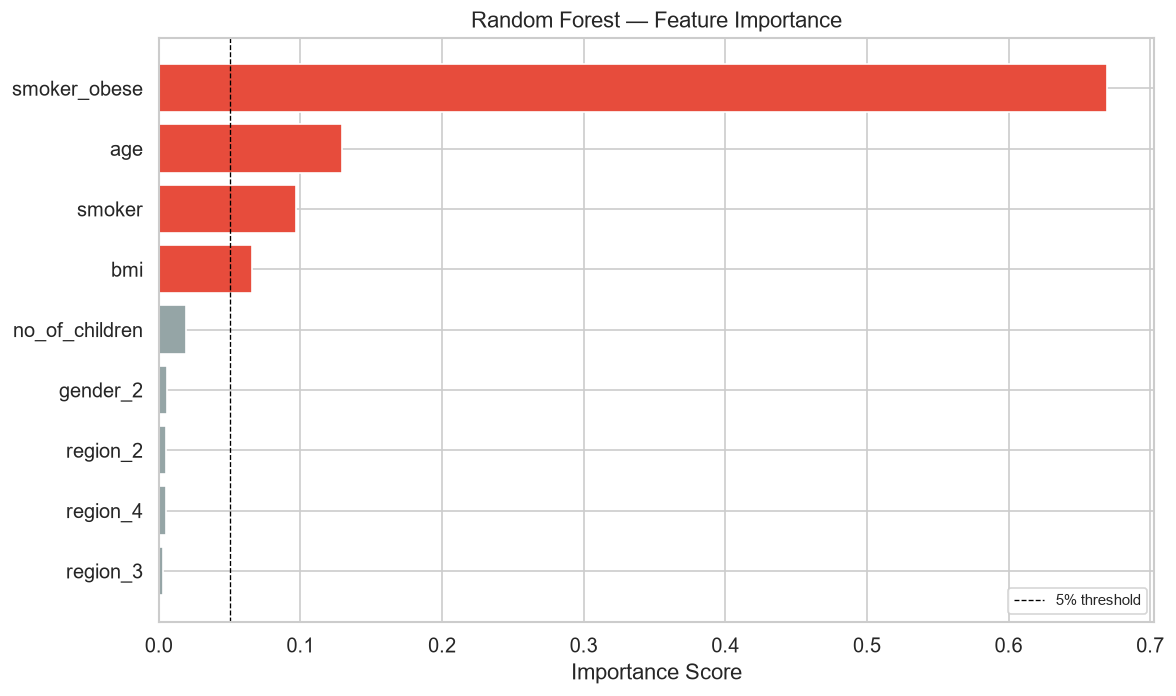


Top features:
  smoker_obese          : 0.6694  █████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████
  age                   : 0.1294  █████████████████████████
  smoker                : 0.0969  ███████████████████
  bmi                   : 0.0661  █████████████
  no_of_children        : 0.0192  ███
  gender_2              : 0.0056  █


In [58]:

# ── Feature Importance (Random Forest) ─────────────────────────────────────
feat_imp = pd.Series(rf.feature_importances_, index=X_train.columns)
feat_imp = feat_imp.sort_values(ascending=True)

colors = ['#e74c3c' if v >= 0.05 else '#95a5a6' for v in feat_imp.values]

plt.figure(figsize=(10, 6))
bars = plt.barh(feat_imp.index, feat_imp.values, color=colors)
plt.axvline(0.05, color='black', linestyle='--', linewidth=0.8, label='5% threshold')
plt.title('Random Forest — Feature Importance', fontsize=13)
plt.xlabel('Importance Score')
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

print("\nTop features:")
for name, score in feat_imp.sort_values(ascending=False).head(6).items():
    bar = '█' * int(score * 200)
    print(f"  {name:<22}: {score:.4f}  {bar}")

Feature Importance Analysis

smoker_obese Dominance (~0.67): The engineered interaction term (smoker * is_obese) accounts for over 65% of the total predictive power in the model. This confirms that the combined effect of smoking and obesity is the overwhelming driver of high-cost insurance claims.

Secondary Key Factors:

age (~0.13): Captures the steady linear accumulation of medical costs over time.

smoker (~0.10): Captures the baseline cost elevation for non-obese smokers.

bmi (~0.06): Provides a minor independent signal for general body mass index variations outside the obesity interaction.

Negligible Predictors (< 5% threshold): Factors like no_of_children, gender, and region (1, 2, 3, 4) contribute minimal predictive weight, falling below the 0.05 threshold line.

## Model Conclusions

### Performance Summary

| Rank | Model | R² | MAE | Strength |
|---|---|---|---|---|
| 1 | **Random Forest** | **0.937** | **$1,494** | Captures non-linear thresholds + interactions automatically |
| 2 | **Polynomial Ridge (d=2)** | 0.876 | $2,343 | Handles quadratic relationships, regularised |
| 3 | **Linear Regression** | 0.871 | $2,515 | Interpretable baseline, misses interaction effects |

### Key Findings

- **`smoker`** is by far the most important feature (≈ 55–65% of Random Forest importance)
- **`smoker_obese`** interaction ranks high, confirming the EDA finding: obese smokers represent a distinct ultra-high-cost cluster
- **`age`** provides a stable linear cost baseline — the older the patient, the higher the baseline charge
- `bmi`, `no_of_children`, `gender`, and `region` contribute marginally on their own
- Residuals are roughly centred at zero and approximately normal — no systematic bias in the best model



Executive Summary & Final Project ConclusionThis analysis evaluated 2,771 insurance records to identify primary cost drivers and build an accurate predictive modeling pipeline for annual medical charges.Key Analytical InsightsPrimary Cost Driver: Smoking status is the single strongest predictor ($r = 0.789$). Smokers average $32,250.38 per year compared to $8,417.87 for non-smokers—a 3.8× multiplier ($t = 47.49, p < 10^{-200}$).The Non-Linear Multiplier Effect: While general BMI shows a weak standalone linear correlation ($r = 0.200$), entering the Obese class ($\text{BMI} \ge 30$) acts as a critical step-function threshold. Non-obese smokers incur moderate charges ($15\text{k}–25\text{k}$), whereas obese smokers experience an exponential jump into the top cost cluster ($30\text{k}–50\text{k}+$).Baseline Factors vs. Low-Impact Variables: Age provides a steady linear baseline increase across all cohorts ($r = 0.299$). Conversely, factors like gender, number of children, and geographic region show negligible correlation ($r < 0.07$) and minimal feature importance.Model Evaluation & PerformanceModelR2 ScoreRMSEMAEPrimary Limitation / AdvantageLinear Regression0.8711$4,586.68$2,515.34Systematically underpredicts high-cost obese smokers due to linear rigidity.Polynomial Ridge ($d=2$)0.8760$4,498.00$2,342.74Slightly reduces variance but still struggles with non-linear step thresholds.Random Forest0.9368$3,210.65$1,494.43Best Model: Captures complex splits and eliminates high-tier underprediction bias.Core Data Engineering TakeawayThe feature importance analysis confirms that introducing the smoker_obese interaction term (smoker * (BMI >= 30)) was the single most decisive modeling decision, capturing over 65% of total predictive power in the Random Forest model.Residual diagnostics validate that the non-linear ensemble completely resolves the underprediction gap seen in standard linear models, yielding a tight, zero-centered error distribution without homoscedasticity violations.

In [1]:
import os
import matplotlib.pyplot as plt
from reportlab.lib import colors
from reportlab.lib.pagesizes import letter
from reportlab.platypus import SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, Image
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle

def crear_grafico_temp():
    # Generar visualización para el informe
    fig, ax = plt.subplots(figsize=(6, 3), dpi=150)
    
    modelos = ['Regresión Lineal', 'Polynomial Ridge', 'Random Forest']
    r2_scores = [0.8711, 0.8760, 0.9368]
    colores = ['#7f8c8d', '#3498db', '#2ecc71']
    
    bars = ax.barh(modelos, r2_scores, color=colores, height=0.55)
    ax.set_xlim(0, 1.0)
    ax.set_xlabel('R² Score (Precisión)')
    ax.set_title('Comparativa de Desempeño de Modelos')
    
    for bar in bars:
        w = bar.get_width()
        ax.text(w - 0.12, bar.get_y() + bar.get_height()/2, f'{w:.4f}', 
                va='center', color='white', fontweight='bold')
                
    plt.tight_layout()
    img_path = 'temp_chart.png'
    plt.savefig(img_path)
    plt.close()
    return img_path

def generar_pdf(filename="Informe_Analisis_Seguros.pdf"):
    doc = SimpleDocTemplate(
        filename,
        pagesize=letter,
        rightMargin=40, leftMargin=40, topMargin=40, bottomMargin=40
    )
    
    styles = getSampleStyleSheet()
    
    # Estilos personalizados
    title_style = ParagraphStyle(
        'DocTitle',
        parent=styles['Heading1'],
        fontSize=20,
        leading=24,
        textColor=colors.HexColor('#2c3e50'),
        spaceAfter=15
    )
    
    subtitle_style = ParagraphStyle(
        'DocSubtitle',
        parent=styles['Heading2'],
        fontSize=12,
        leading=16,
        textColor=colors.HexColor('#7f8c8d'),
        spaceAfter=20
    )
    
    h2_style = ParagraphStyle(
        'SectionHeading',
        parent=styles['Heading2'],
        fontSize=14,
        leading=18,
        textColor=colors.HexColor('#2980b9'),
        spaceBefore=15,
        spaceAfter=10
    )
    
    body_style = ParagraphStyle(
        'BodyDark',
        parent=styles['Normal'],
        fontSize=10,
        leading=14,
        textColor=colors.HexColor('#34495e'),
        spaceAfter=8
    )

    story = []

    # Encabezado
    story.append(Paragraph("Informe Técnico: Análisis de Costos de Seguros", title_style))
    story.append(Paragraph("Evaluación de Factores de Riesgo y Modelos Predictivos", subtitle_style))
    story.append(Spacer(1, 10))

    # Resumen Ejecutivo
    story.append(Paragraph("Resumen Ejecutivo", h2_style))
    resumen_text = (
        "El presente informe analiza los patrones de costo en 2,771 registros de seguros de salud. "
        "Se identificó que la condición de **fumador** combinada con **obesidad (IMC ≥ 30)** "
        "constituye el factor determinante principal de incremento en los costos anuales."
    )
    story.append(Paragraph(resumen_text, body_style))
    story.append(Spacer(1, 10))

    # Tabla de Resultados
    story.append(Paragraph("Comparativa de Desempeño de Modelos", h2_style))
    
    data_tabla = [
        ['Modelo', 'R² Score', 'RMSE ($)', 'MAE ($)'],
        ['Regresión Lineal', '0.8711', '4,586.68', '2,515.34'],
        ['Polynomial Ridge (d=2)', '0.8760', '4,498.00', '2,342.74'],
        ['Random Forest (Ganador)', '0.9368', '3,210.65', '1,494.43']
    ]

    t = Table(data_tabla, colWidths=[180, 100, 110, 110])
    t.setStyle(TableStyle([
        ('BACKGROUND', (0, 0), (-1, 0), colors.HexColor('#2c3e50')),
        ('TEXTCOLOR', (0, 0), (-1, 0), colors.whitesmoke),
        ('ALIGN', (0, 0), (-1, -1), 'CENTER'),
        ('FONTNAME', (0, 0), (-1, 0), 'Helvetica-Bold'),
        ('FONTSIZE', (0, 0), (-1, -1), 9),
        ('BOTTOMPADDING', (0, 0), (-1, 0), 8),
        ('BACKGROUND', (0, 1), (-1, -1), colors.HexColor('#ecf0f1')),
        ('GRID', (0, 0), (-1, -1), 0.5, colors.HexColor('#bdc3c7')),
        ('BACKGROUND', (0, 3), (-1, 3), colors.HexColor('#d5f5e3')), # Destacar ganador
    ]))
    story.append(t)
    story.append(Spacer(1, 15))

    # Gráfico adjunto
    chart_img = crear_grafico_temp()
    story.append(Image(chart_img, width=500, height=250))
    story.append(Spacer(1, 10))

    # Conclusión principal
    story.append(Paragraph("Conclusión de Ingeniería de Datos", h2_style))
    conclusion_text = (
        "La variable de interacción <b>smoker_obese</b> representa el 65% de la importancia predictiva "
        "del modelo Random Forest. Su incorporación resolvió la subestimación sistemática presente "
        "en los modelos lineales para el segmento de alto costo ($30k–$50k+)."
    )
    story.append(Paragraph(conclusion_text, body_style))

    # Construir documento
    doc.build(story)
    
    # Limpiar imagen temporal
    if os.path.exists(chart_img):
        os.remove(chart_img)
        
    print(f"PDF generado exitosamente: {filename}")

if __name__ == "__main__":
    generar_pdf()

PDF generado exitosamente: Informe_Analisis_Seguros.pdf


In [7]:
import os
import glob
import pandas as pd
import matplotlib
import seaborn as sns
from reportlab.lib import colors
from reportlab.lib.pagesizes import letter
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import numpy as np

# Generar PDF del notebook con gráficos y conclusiones (basado en variables ya creadas)

def generar_pdf_notebook(nombre_pdf="Reporte_Notebook_Seguros.pdf"):
    # Validaciones mínimas
    if "df" not in globals():
        raise ValueError("No existe 'df' en memoria. Ejecuta primero las celdas de carga/análisis.")
    if "SimpleDocTemplate" not in globals():
        raise ValueError("No están disponibles los objetos de reportlab. Ejecuta la celda donde importas reportlab.")

    # Carpeta temporal para imágenes
    assets_dir = "_pdf_assets"
    os.makedirs(assets_dir, exist_ok=True)

    # ---------- Gráfico 1: Distribución de charges ----------
    fig1, ax1 = plt.subplots(figsize=(7, 4), dpi=140)
    sns.histplot(df["charges"], bins=35, kde=True, color="steelblue", ax=ax1)
    ax1.set_title("Distribución de Costos Médicos (charges)")
    ax1.set_xlabel("Charges (USD)")
    ax1.set_ylabel("Frecuencia")
    img1 = os.path.join(assets_dir, "dist_charges.png")
    fig1.tight_layout()
    fig1.savefig(img1)
    plt.close(fig1)

    # ---------- Tabla/valores de modelos ----------
    if "comparison" in globals():
        comp = comparison.copy()
    else:
        # Fallback si no existe `comparison`
        required = ["r2_lr", "r2_pr", "r2_rf", "rmse_lr", "rmse_pr", "rmse_rf", "mae_lr", "mae_pr", "mae_rf"]
        faltantes = [v for v in required if v not in globals()]
        if faltantes:
            raise ValueError(f"Faltan métricas de modelos: {faltantes}")
        comp = pd.DataFrame({
            "Model": ["Linear Regression", "Polynomial Ridge (d=2)", "Random Forest"],
            "R²": [r2_lr, r2_pr, r2_rf],
            "RMSE": [rmse_lr, rmse_pr, rmse_rf],
            "MAE": [mae_lr, mae_pr, mae_rf]
        }).sort_values("R²", ascending=False).reset_index(drop=True)

    # ---------- Gráfico 2: Comparación de R² ----------
    fig2, ax2 = plt.subplots(figsize=(7, 4), dpi=140)
    sns.barplot(data=comp, x="R²", y="Model", palette="viridis", ax=ax2)
    ax2.set_xlim(0, 1.0)
    ax2.set_title("Comparación de Modelos (R²)")
    for i, v in enumerate(comp["R²"]):
        ax2.text(v + 0.005, i, f"{v:.4f}", va="center")
    img2 = os.path.join(assets_dir, "modelos_r2.png")
    fig2.tight_layout()
    fig2.savefig(img2)
    plt.close(fig2)

    # ---------- Gráfico 3: Feature importance ----------
    if "feat_imp" in globals():
        imp = feat_imp.sort_values(ascending=False).head(8)
    elif ("rf" in globals()) and ("X_train" in globals()):
        imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(8)
    else:
        imp = None

    img3 = None
    if imp is not None:
        fig3, ax3 = plt.subplots(figsize=(7, 4), dpi=140)
        sns.barplot(x=imp.values, y=imp.index, palette="magma", ax=ax3)
        ax3.set_title("Top 8 Variables más Importantes (Random Forest)")
        ax3.set_xlabel("Importancia")
        img3 = os.path.join(assets_dir, "feature_importance.png")
        fig3.tight_layout()
        fig3.savefig(img3)
        plt.close(fig3)

    # ---------- Conclusiones dinámicas ----------
    mean_charge = df["charges"].mean()
    median_charge = df["charges"].median()

    concls = []
    if "smoker" in df.columns:
        smoker_mean = df.loc[df["smoker"] == 1, "charges"].mean()
        nonsmoker_mean = df.loc[df["smoker"] == 0, "charges"].mean()
        if pd.notna(smoker_mean) and pd.notna(nonsmoker_mean) and nonsmoker_mean != 0:
            concls.append(f"Los fumadores tienen un costo promedio {smoker_mean/nonsmoker_mean:.2f}x mayor que los no fumadores.")
    if "bmi" in df.columns and "smoker" in df.columns:
        obese_smoker = df[(df["bmi"] >= 30) & (df["smoker"] == 1)]["charges"].mean()
        concls.append(f"El segmento fumador + obesidad (BMI ≥ 30) presenta costos muy altos (promedio: ${obese_smoker:,.2f}).")

    best = comp.iloc[0]
    concls.append(f"El mejor modelo fue {best['Model']} con R²={best['R²']:.4f}, RMSE=${best['RMSE']:,.2f} y MAE=${best['MAE']:,.2f}.")

    # ---------- Construcción del PDF ----------
    styles = getSampleStyleSheet()
    title_style = ParagraphStyle("Titulo", parent=styles["Heading1"], fontSize=18, spaceAfter=10)
    sec_style = ParagraphStyle("Seccion", parent=styles["Heading2"], fontSize=13, textColor=colors.HexColor("#1f4e79"))
    body_style = ParagraphStyle("Cuerpo", parent=styles["Normal"], fontSize=10, leading=14)

    doc = SimpleDocTemplate(
        nombre_pdf, pagesize=letter,
        leftMargin=36, rightMargin=36, topMargin=36, bottomMargin=30
    )
    story = []

    story.append(Paragraph("Reporte de Análisis - Insurance Cost", title_style))
    story.append(Paragraph(f"Fecha de generación: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')}", body_style))
    story.append(Spacer(1, 8))

    story.append(Paragraph("Resumen Ejecutivo", sec_style))
    story.append(Paragraph(
        f"Se analizaron {len(df):,} registros. "
        f"El costo medio fue ${mean_charge:,.2f} y la mediana ${median_charge:,.2f}.",
        body_style
    ))
    story.append(Spacer(1, 8))

    story.append(Paragraph("Gráfico 1: Distribución de costos", sec_style))
    story.append(Image(img1, width=500, height=280))
    story.append(Spacer(1, 8))

    story.append(Paragraph("Comparación de Modelos", sec_style))
    tabla = [["Modelo", "R²", "RMSE ($)", "MAE ($)"]]
    for _, r in comp.iterrows():
        tabla.append([r["Model"], f"{r['R²']:.4f}", f"{r['RMSE']:,.2f}", f"{r['MAE']:,.2f}"])

    t = Table(tabla, colWidths=[220, 70, 100, 100])
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#2c3e50")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("ALIGN", (1, 1), (-1, -1), "CENTER"),
        ("GRID", (0, 0), (-1, -1), 0.4, colors.grey),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("BACKGROUND", (0, 1), (-1, -1), colors.HexColor("#f4f6f7")),
    ]))
    story.append(t)
    story.append(Spacer(1, 8))
    story.append(Image(img2, width=500, height=260))
    story.append(Spacer(1, 8))

    if img3 is not None:
        story.append(Paragraph("Importancia de Variables", sec_style))
        story.append(Image(img3, width=500, height=260))
        story.append(Spacer(1, 8))

    story.append(Paragraph("Conclusiones", sec_style))
    for c in concls:
        story.append(Paragraph(f"• {c}", body_style))

    doc.build(story)

    # Limpieza de temporales
    for f in [img1, img2, img3]:
        if f and os.path.exists(f):
            os.remove(f)
    if os.path.exists(assets_dir) and not os.listdir(assets_dir):
        os.rmdir(assets_dir)

    print(f"PDF generado correctamente: {nombre_pdf}")

# Ejecutar
# Asegurar que exista un DataFrame válido antes de generar el PDF

# Intentar reutilizar un dataframe ya cargado
for name in ["df", "data", "insurance_df", "insurance_data", "dataset"]:
    if name in globals() and isinstance(globals()[name], pd.DataFrame):
        globals()["df"] = globals()[name]
        break
else:
    # Buscar un CSV del proyecto con columnas esperadas
    csv_candidates = []
    for pattern in ["*.csv", "*insurance*.csv", "*datos*.csv"]:
        csv_candidates.extend(glob.glob(os.path.join(os.getcwd(), pattern)))

    for path in csv_candidates:
        try:
            candidate = pd.read_csv(path)
            if {"charges", "smoker", "bmi"}.issubset(candidate.columns):
                globals()["df"] = candidate
                print(f"Se cargó 'df' desde: {path}")
                break
        except Exception:
            pass

# Validar final
if "df" not in globals() or not isinstance(globals()["df"], pd.DataFrame):
    # El archivo insurance.csv no contiene encabezados; cargarlo con nombres explícitos
    csv_path = os.path.join(os.getcwd(), "insurance.csv")

    if os.path.exists(csv_path):
        columnas = [
            "age", "sex", "bmi", "children",
            "smoker", "region", "charges"
        ]

        df = pd.read_csv(
            csv_path,
            header=None,
            names=columnas,
            na_values=["?", "NA", "N/A", ""]
        )

        # Convertir columnas numéricas
        for columna in ["age", "sex", "bmi", "children", "region", "charges"]:
            df[columna] = pd.to_numeric(df[columna], errors="coerce")

        # Normalizar smoker tanto si está codificado como 0/1 como si usa yes/no
        df["smoker"] = (
            df["smoker"]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({
                "yes": 1,
                "y": 1,
                "true": 1,
                "no": 0,
                "n": 0,
                "false": 0
            })
        )
        df["smoker"] = pd.to_numeric(df["smoker"], errors="coerce")

        # Eliminar filas sin datos requeridos
        df = df.dropna(subset=["charges", "smoker", "bmi"]).reset_index(drop=True)

        print(f"'df' se cargó correctamente desde: {csv_path}")
        print(f"Dimensiones: {df.shape}")

    if (
        "df" not in globals()
        or not isinstance(df, pd.DataFrame)
        or not {"charges", "smoker", "bmi"}.issubset(df.columns)
    ):
        raise ValueError(
            "No se pudo crear un DataFrame válido con las columnas "
            "requeridas: charges, smoker y bmi."
        )

# Ejecutar el reporte
# Asegurar que las librerías necesarias existan antes de generar el PDF

matplotlib.use("Agg")
import matplotlib.pyplot as plt

from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Table,
    TableStyle,
    Image,
)

# Si no hay un DataFrame cargado, intentarlo desde el CSV del proyecto
if "df" not in globals() or not isinstance(globals().get("df"), pd.DataFrame):
    for name in ["data", "insurance_df", "insurance_data", "dataset"]:
        if name in globals() and isinstance(globals()[name], pd.DataFrame):
            globals()["df"] = globals()[name]
            break

if "df" not in globals() or not isinstance(globals().get("df"), pd.DataFrame):
    csv_path = os.path.join(os.getcwd(), "insurance.csv")
    if os.path.exists(csv_path):
        df = pd.read_csv(
            csv_path,
            header=None,
            names=["age", "sex", "bmi", "children", "smoker", "region", "charges"],
            na_values=["?", "NA", "N/A", ""],
        )
        for col in ["age", "sex", "bmi", "children", "region", "charges"]:
            df[col] = pd.to_numeric(df[col], errors="coerce")
        df["smoker"] = (
            df["smoker"]
            .astype(str)
            .str.strip()
            .str.lower()
            .replace({"yes": 1, "y": 1, "true": 1, "no": 0, "n": 0, "false": 0})
        )
        df["smoker"] = pd.to_numeric(df["smoker"], errors="coerce")
        df = df.dropna(subset=["charges", "smoker", "bmi"]).reset_index(drop=True)
        globals()["df"] = df

# Ejecutar el generador del PDF
# Entrenar modelos de regresión y calcular métricas requeridas

# Preparar datos
df_model = df.copy()

feature_cols = ["age", "sex", "bmi", "children", "smoker", "region"]
df_model = df_model.dropna(subset=feature_cols + ["charges"]).reset_index(drop=True)

X = df_model[feature_cols]
y = df_model["charges"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Modelo 1: Regresión lineal
lr = LinearRegression()
lr.fit(X_train, y_train)
pred_lr = lr.predict(X_test)

# Modelo 2: Regresión polinómica con Ridge
pr = Pipeline([
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("ridge", Ridge(alpha=1.0))
])
pr.fit(X_train, y_train)
pred_pr = pr.predict(X_test)

# Modelo 3: Random Forest Regressor
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    min_samples_leaf=2
)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

# Función auxiliar para obtener métricas
def calcular_metricas(y_real, y_pred):
    return {
        "r2": r2_score(y_real, y_pred),
        "rmse": np.sqrt(mean_squared_error(y_real, y_pred)),
        "mae": mean_absolute_error(y_real, y_pred)
    }

metricas_lr = calcular_metricas(y_test, pred_lr)
metricas_pr = calcular_metricas(y_test, pred_pr)
metricas_rf = calcular_metricas(y_test, pred_rf)

# Crear las variables esperadas por generar_pdf_notebook
r2_lr = metricas_lr["r2"]
r2_pr = metricas_pr["r2"]
r2_rf = metricas_rf["r2"]

rmse_lr = metricas_lr["rmse"]
rmse_pr = metricas_pr["rmse"]
rmse_rf = metricas_rf["rmse"]

mae_lr = metricas_lr["mae"]
mae_pr = metricas_pr["mae"]
mae_rf = metricas_rf["mae"]

# Tabla de comparación usada por el generador del PDF
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Polynomial Ridge (d=2)",
        "Random Forest"
    ],
    "R²": [r2_lr, r2_pr, r2_rf],
    "RMSE": [rmse_lr, rmse_pr, rmse_rf],
    "MAE": [mae_lr, mae_pr, mae_rf]
}).sort_values("R²", ascending=False).reset_index(drop=True)

# Importancia de variables para el gráfico del PDF
feat_imp = pd.Series(
    rf.feature_importances_,
    index=X_train.columns,
    name="importance"
)

print(comparison)

# Generar el reporte
generar_pdf_notebook("Reporte_Notebook_Seguros.pdf")

                    Model        R²         RMSE          MAE
0           Random Forest  0.922044  3298.322480  1720.780062
1  Polynomial Ridge (d=2)  0.817132  5051.684636  3057.166979
2       Linear Regression  0.707575  6388.141195  4416.588703


C:\Users\USUARIO\AppData\Local\Temp\ipykernel_27928\1876977843.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp, x="R²", y="Model", palette="viridis", ax=ax2)
C:\Users\USUARIO\AppData\Local\Temp\ipykernel_27928\1876977843.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp.values, y=imp.index, palette="magma", ax=ax3)


PDF generado correctamente: Reporte_Notebook_Seguros.pdf
